In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
df = pd.read_csv("../dataset/processed/CLEANED-FINAL.csv")

df.head()

,review_title,review_text,combined_text_no_rating,final_model_text_no_rating,rating,product_name,brand,category
0,... 3 of them and one of the item is bad quali...,I order 3 of them and one of the item is bad q...,i order 3 of them and one of the item is bad q...,order 3 one item bad quality miss backup sprin...,3,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."
1,... always the less expensive way to go for pr...,Bulk is always the less expensive way to go fo...,bulk is always the less expensive way to go fo...,bulk always less expensive way go product like,4,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."
2,... are not Duracell but for the price i am ha...,Well they are not Duracell but for the price i...,well they are not duracell but for the price i...,well not duracell price happy,5,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."
3,... as well as name brand batteries at a much ...,Seem to work as well as name brand batteries a...,... as well as name brand batteries at a much ...,well name brand battery much well seem work we...,5,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."
4,... batteries are very long lasting the price ...,These batteries are very long lasting the pric...,these batteries are very long lasting the pric...,battery long lasting price great,5,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nRating Distribution:")
print(df["rating"].value_counts().sort_index())

Dataset Shape: (28332, 8)

Columns:
['review_title', 'review_text', 'combined_text_no_rating', 'final_model_text_no_rating', 'rating', 'product_name', 'brand', 'category']

Missing Values:
review_title                   0
review_text                    0
combined_text_no_rating        2
final_model_text_no_rating    21
rating                         0
product_name                   0
brand                          0
category                       0
dtype: int64

Rating Distribution:
rating
1      965
2      616
3     1206
4     5648
5    19897
Name: count, dtype: int64


In [4]:
# Check missing values in selected columns

print("Missing review texts:",
      df["final_model_text_no_rating"].isnull().sum())

print("Missing ratings:",
      df["rating"].isnull().sum())

Missing review texts: 21
Missing ratings: 0


In [5]:
# Remove rows with missing or empty review text

df = df.dropna(subset=["final_model_text_no_rating", "rating"])

df = df[
    df["final_model_text_no_rating"].str.strip() != ""
]

print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (28311, 8)


In [6]:
X = df["final_model_text_no_rating"]

y = df["rating"]

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (28311,)
Output shape: (28311,)


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining rating distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting rating distribution:")
print(y_test.value_counts().sort_index())

Training data: (22648,)
Testing data: (5663,)

Training rating distribution:
rating
1      772
2      493
3      964
4     4517
5    15902
Name: count, dtype: int64

Testing rating distribution:
rating
1     193
2     123
3     241
4    1130
5    3976
Name: count, dtype: int64


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

# Learn vocabulary and transform training reviews
X_train_tfidf = tfidf.fit_transform(X_train)    

# Transform testing reviews using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

# Display shapes
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

print("Total vocabulary features:", len(tfidf.vocabulary_))

Training TF-IDF shape: (22648, 5000)
Testing TF-IDF shape: (5663, 5000)
Total vocabulary features: 5000


In [9]:
from sklearn.linear_model import LinearRegression

# Initialize Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train_tfidf, y_train)

print("Linear Regression model training completed!")

Linear Regression model training completed!


In [10]:
# Predict ratings using testing data
y_pred = lr_model.predict(X_test_tfidf)

# Display first 10 predictions
results = pd.DataFrame({
    "Actual Rating": y_test.values[:10],
    "Predicted Rating": y_pred[:10]
})

print(results)

   Actual Rating  Predicted Rating
0              5          4.829614
1              5          4.877041
2              5          5.036715
3              5          5.466666
4              5          5.083682
5              4          4.388113
6              5          2.221895
7              5          5.496140
8              5          4.425397
9              4          4.270988


In [11]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("Linear Regression Performance")
print("--------------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Performance
--------------------------------
MAE: 0.4641486183315563
MSE: 0.4211903451434997
RMSE: 0.6489917912758987
R2 Score: 0.5182056457039625


In [12]:
from sklearn.linear_model import Ridge

# Initialize Ridge Regression
ridge_model = Ridge(alpha=1.0)

# Train the model
ridge_model.fit(X_train_tfidf, y_train)

print("Ridge Regression model training completed!")

Ridge Regression model training completed!


In [13]:
# Predict ratings
ridge_pred = ridge_model.predict(X_test_tfidf)

# Evaluate performance
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression Performance")
print("--------------------------------")
print("MAE:", ridge_mae)
print("MSE:", ridge_mse)
print("RMSE:", ridge_rmse)
print("R2 Score:", ridge_r2)

Ridge Regression Performance
--------------------------------
MAE: 0.43138112065729517
MSE: 0.3658684109190663
RMSE: 0.604870573692477
R2 Score: 0.5814877125542551


In [14]:
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression"
    ],
    "MAE": [
        mae,
        ridge_mae
    ],
    "MSE": [
        mse,
        ridge_mse
    ],
    "RMSE": [
        rmse,
        ridge_rmse
    ],
    "R2 Score": [
        r2,
        ridge_r2
    ]
})

model_results


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.464149,0.421190,0.648992,0.518206
1,Ridge Regression,0.431381,0.365868,0.604871,0.581488


In [15]:
from sklearn.ensemble import RandomForestRegressor

# Initialize Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_tfidf, y_train)

print("Random Forest model training completed!")

Random Forest model training completed!


In [16]:
# Predict ratings
rf_pred = rf_model.predict(X_test_tfidf)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mse = mean_squared_error(y_test, rf_pred)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_pred)

# Display results
print("Random Forest Performance")
print("--------------------------------")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Performance
--------------------------------
MAE: 0.45695282596743053
MSE: 0.42170331340091716
RMSE: 0.6493868749835626
R2 Score: 0.5176188677466649


In [17]:
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Random Forest"
    ],
    "MAE": [
        mae,
        ridge_mae,
        rf_mae
    ],
    "MSE": [
        mse,
        ridge_mse,
        rf_mse
    ],
    "RMSE": [
        rmse,
        ridge_rmse,
        rf_rmse
    ],
    "R2 Score": [
        r2,
        ridge_r2,
        rf_r2
    ]
})

model_results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.464149,0.421190,0.648992,0.518206
1,Ridge Regression,0.431381,0.365868,0.604871,0.581488
2,Random Forest,0.456953,0.421703,0.649387,0.517619


In [18]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge

param_grid = {
    "alpha": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0]
}

In [19]:
ridge = Ridge()

grid_search = GridSearchCV(
    estimator=ridge,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Train using training data only
grid_search.fit(X_train_tfidf, y_train)

print("Best Alpha:", grid_search.best_params_["alpha"])
print("Best Cross-Validation MAE:", -grid_search.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Alpha: 1.0
Best Cross-Validation MAE: 0.44078551361298535


In [20]:
# Retrieve the best model
best_ridge_model = grid_search.best_estimator_

print("Best Ridge model retrieved successfully!")

Best Ridge model retrieved successfully!


In [21]:
# Predict ratings
tuned_ridge_pred = best_ridge_model.predict(X_test_tfidf)

# Calculate metrics
tuned_mae = mean_absolute_error(y_test, tuned_ridge_pred)

tuned_mse = mean_squared_error(y_test, tuned_ridge_pred)

tuned_rmse = np.sqrt(tuned_mse)

tuned_r2 = r2_score(y_test, tuned_ridge_pred)

print("Tuned Ridge Regression Performance")
print("--------------------------------")
print("MAE:", tuned_mae)
print("MSE:", tuned_mse)
print("RMSE:", tuned_rmse)
print("R2 Score:", tuned_r2)

Tuned Ridge Regression Performance
--------------------------------
MAE: 0.43138112065729517
MSE: 0.3658684109190663
RMSE: 0.604870573692477
R2 Score: 0.5814877125542551


In [22]:
evaluation_df = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": tuned_ridge_pred
})

evaluation_df["Absolute Error"] = (
    evaluation_df["Actual Rating"] -
    evaluation_df["Predicted Rating"]
).abs()

rating_wise = evaluation_df.groupby("Actual Rating").agg(
    Review_Count=("Predicted Rating", "count"),
    MAE=("Absolute Error", "mean"),
    Average_Predicted_Rating=("Predicted Rating", "mean")
)

print(rating_wise)

               Review_Count       MAE  Average_Predicted_Rating
Actual Rating                                                  
1                       193  1.497091                  2.436426
2                       123  0.894079                  2.755788
3                       241  0.781379                  3.568742
4                      1130  0.531478                  4.408333
5                      3976  0.315674                  4.755209


In [23]:
# Calculate average rating from training data
baseline_value = y_train.mean()

# Predict the same rating for every test review
baseline_pred = np.full(len(y_test), baseline_value)

# Evaluate baseline
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_pred)

print("Mean Baseline Performance")
print("-------------------------")
print("Baseline Rating:", baseline_value)
print("MAE:", baseline_mae)
print("MSE:", baseline_mse)
print("RMSE:", baseline_rmse)
print("R2 Score:", baseline_r2)

Mean Baseline Performance
-------------------------
Baseline Rating: 4.5137760508654186
MAE: 0.6826711318327842
MSE: 0.874211880939645
RMSE: 0.9349929844333833
R2 Score: -8.432626596999171e-09


In [24]:
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.linear_model import Ridge

# Calculate sample weights based on rating distribution
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Create a new Ridge model
weighted_ridge = Ridge(alpha=1.0)

# Train using sample weights
weighted_ridge.fit(
    X_train_tfidf,
    y_train,
    sample_weight=sample_weights
)

print("Class-balanced Ridge model training completed!")

Class-balanced Ridge model training completed!


In [25]:
# Generate predictions
weighted_pred = weighted_ridge.predict(X_test_tfidf)

# Calculate evaluation metrics
weighted_mae = mean_absolute_error(y_test, weighted_pred)
weighted_mse = mean_squared_error(y_test, weighted_pred)
weighted_rmse = np.sqrt(weighted_mse)
weighted_r2 = r2_score(y_test, weighted_pred)

print("Class-Balanced Ridge Regression Performance")
print("-------------------------------------------")
print("MAE:", weighted_mae)
print("MSE:", weighted_mse)
print("RMSE:", weighted_rmse)
print("R2 Score:", weighted_r2)

Class-Balanced Ridge Regression Performance
-------------------------------------------
MAE: 0.6303956228350013
MSE: 0.6560515831187486
RMSE: 0.8099701124848673
R2 Score: 0.24955082062505174


In [26]:
weighted_evaluation_df = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": weighted_pred
})

weighted_evaluation_df["Absolute Error"] = (
    weighted_evaluation_df["Actual Rating"] -
    weighted_evaluation_df["Predicted Rating"]
).abs()

weighted_rating_wise = weighted_evaluation_df.groupby(
    "Actual Rating"
).agg(
    Review_Count=("Predicted Rating", "count"),
    MAE=("Absolute Error", "mean"),
    Average_Predicted_Rating=("Predicted Rating", "mean")
)

print(weighted_rating_wise)

               Review_Count       MAE  Average_Predicted_Rating
Actual Rating                                                  
1                       193  0.797745                  1.687372
2                       123  0.498173                  2.178977
3                       241  0.550447                  3.050609
4                      1130  0.481460                  4.099003
5                      3976  0.673537                  4.400039


In [27]:
rating_comparison = pd.DataFrame({
    "Rating": [1, 2, 3, 4, 5],
    "Original Ridge": [
        1.497091,
        0.894079,
        0.781379,
        0.531478,
        0.315674
    ],
    "Weighted Ridge": [
        0.797745,
        0.498173,
        0.550447,
        0.481460,
        0.673537
    ]
})

rating_comparison

,Rating,Original Ridge,Weighted Ridge
0,1,1.497091,0.797745
1,2,0.894079,0.498173
2,3,0.781379,0.550447
3,4,0.531478,0.481460
4,5,0.315674,0.673537


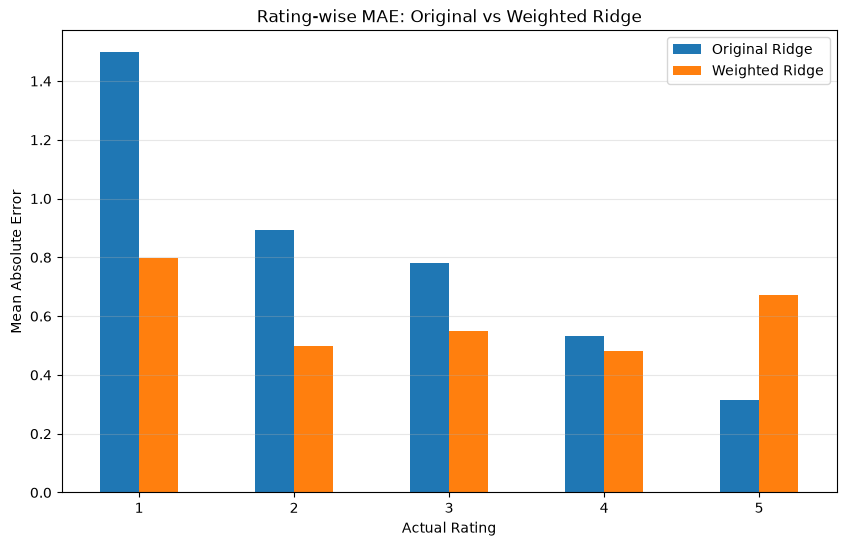

In [28]:
rating_comparison.plot(
    x="Rating",
    y=["Original Ridge", "Weighted Ridge"],
    kind="bar",
    figsize=(10, 6)
)

plt.title("Rating-wise MAE: Original vs Weighted Ridge")
plt.xlabel("Actual Rating")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

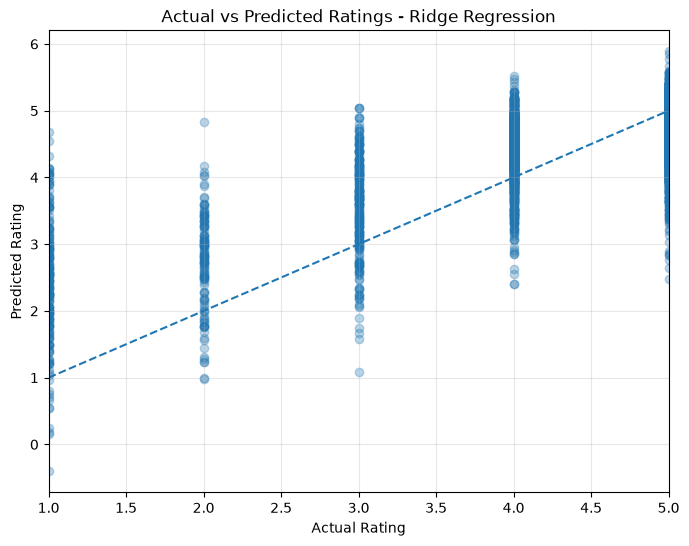

In [29]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    tuned_ridge_pred,
    alpha=0.3
)

# Perfect prediction reference line
plt.plot(
    [1, 5],
    [1, 5],
    linestyle="--"
)

plt.title("Actual vs Predicted Ratings - Ridge Regression")
plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")

plt.xlim(1, 5)
plt.grid(alpha=0.3)

plt.show()

In [30]:
# Create residuals
residuals = y_test.values - tuned_ridge_pred

# Display residual statistics
print("Residual Analysis")
print("-----------------")
print("Mean Residual:", np.mean(residuals))
print("Standard Deviation:", np.std(residuals))
print("Minimum Residual:", np.min(residuals))
print("Maximum Residual:", np.max(residuals))

Residual Analysis
-----------------
Mean Residual: 0.0008147818756391161
Standard Deviation: 0.6048700249223476
Minimum Residual: -3.679590694520358
Maximum Residual: 2.5215465561361183


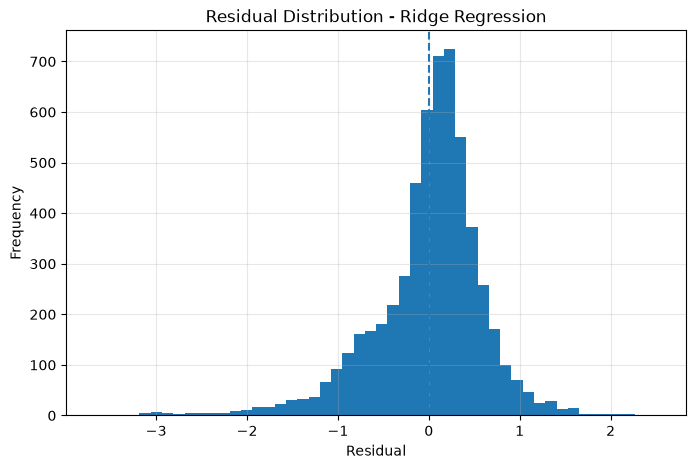

In [31]:
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=50)

plt.title("Residual Distribution - Ridge Regression")
plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.axvline(0, linestyle="--")

plt.grid(alpha=0.3)
plt.show()

In [32]:
import joblib
import os

# Create directory if it doesn't exist
os.makedirs("../models/regression", exist_ok=True)

# Save Ridge Regression model
joblib.dump(
    best_ridge_model,
    "../models/regression/ridge_rating_model.pkl"
)

# Save TF-IDF vectorizer
joblib.dump(
    tfidf,
    "../models/regression/tfidf_vectorizer.pkl"
)

print("Ridge model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

Ridge model saved successfully!
TF-IDF vectorizer saved successfully!


In [33]:
import joblib

loaded_model = joblib.load(
    "../models/regression/ridge_rating_model.pkl"
)

loaded_tfidf = joblib.load(
    "../models/regression/tfidf_vectorizer.pkl"
)

print("Model and vectorizer loaded successfully!")

Model and vectorizer loaded successfully!


In [34]:
new_review = [
    "product excellent quality battery last long highly recommend"
]

new_review_tfidf = loaded_tfidf.transform(new_review)

predicted_rating = loaded_model.predict(new_review_tfidf)

print("Predicted Rating:", predicted_rating[0])

Predicted Rating: 4.914062753873075


In [35]:
final_rating = round(predicted_rating[0])
final_rating = max(1, min(5, final_rating))

print("Predicted Customer Rating:", final_rating, "/ 5")

Predicted Customer Rating: 5 / 5


In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tfidf_experiments = [
    {"max_features": 5000, "ngram_range": (1, 2)},
    {"max_features": 10000, "ngram_range": (1, 2)},
    {"max_features": 15000, "ngram_range": (1, 2)},
    {"max_features": 10000, "ngram_range": (1, 3)},
    {"max_features": 15000, "ngram_range": (1, 3)}
]

results = []

for config in tfidf_experiments:

    print("Testing:", config)

    vectorizer = TfidfVectorizer(
        max_features=config["max_features"],
        ngram_range=config["ngram_range"]
    )

    X_train_new = vectorizer.fit_transform(X_train)
    X_test_new = vectorizer.transform(X_test)

    model = Ridge(alpha=1.0)
    model.fit(X_train_new, y_train)

    predictions = model.predict(X_test_new)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Max Features": config["max_features"],
        "N-gram Range": str(config["ngram_range"]),
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

tfidf_results = pd.DataFrame(results)

tfidf_results.sort_values(
    by="R2 Score",
    ascending=False
)

Testing: {'max_features': 5000, 'ngram_range': (1, 2)}
Testing: {'max_features': 10000, 'ngram_range': (1, 2)}
Testing: {'max_features': 15000, 'ngram_range': (1, 2)}
Testing: {'max_features': 10000, 'ngram_range': (1, 3)}
Testing: {'max_features': 15000, 'ngram_range': (1, 3)}


,Max Features,N-gram Range,MAE,RMSE,R2 Score
4,15000,"(1, 3)",0.392804,0.560650,0.640444
2,15000,"(1, 2)",0.397383,0.566054,0.633479
1,10000,"(1, 2)",0.406770,0.575296,0.621413
3,10000,"(1, 3)",0.406400,0.575553,0.621075
0,5000,"(1, 2)",0.431381,0.604871,0.581488


In [37]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge

# Best TF-IDF configuration
best_tfidf = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 3)
)

X_train_best = best_tfidf.fit_transform(X_train)
X_test_best = best_tfidf.transform(X_test)

# Different alpha values
param_grid = {
    "alpha": [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0]
}

ridge = Ridge()

grid_search = GridSearchCV(
    estimator=ridge,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_best, y_train)

print("Best Alpha:", grid_search.best_params_["alpha"])
print("Best Cross-Validation MAE:", -grid_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Alpha: 0.5
Best Cross-Validation MAE: 0.39832623657823063


In [38]:
# Get the best model from GridSearchCV
best_tuned_ridge = grid_search.best_estimator_

# Predict on test data
tuned_predictions = best_tuned_ridge.predict(X_test_best)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, tuned_predictions)
mse = mean_squared_error(y_test, tuned_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, tuned_predictions)

print("Optimized Ridge Regression Performance")
print("--------------------------------------")
print("Best Alpha:", grid_search.best_params_["alpha"])
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Optimized Ridge Regression Performance
--------------------------------------
Best Alpha: 0.5
MAE: 0.38246643110695033
MSE: 0.30290892781451656
RMSE: 0.5503716270071674
R2 Score: 0.653506275797518


In [39]:
# Combine review title and review text
X_combined = (
    df["review_title"].fillna("") + " " +
    df["final_model_text_no_rating"].fillna("")
)

y_combined = df["rating"]

# Stratified train-test split
X_train_combined, X_test_combined, y_train_combined, y_test_combined = train_test_split(
    X_combined,
    y_combined,
    test_size=0.2,
    random_state=42,
    stratify=y_combined
)

print("Training data:", X_train_combined.shape)
print("Testing data:", X_test_combined.shape)

Training data: (22648,)
Testing data: (5663,)


In [40]:
# TF-IDF for title + review text
combined_tfidf = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 3)
)

X_train_combined_tfidf = combined_tfidf.fit_transform(
    X_train_combined
)

X_test_combined_tfidf = combined_tfidf.transform(
    X_test_combined
)

print("Training TF-IDF shape:", X_train_combined_tfidf.shape)
print("Testing TF-IDF shape:", X_test_combined_tfidf.shape)

Training TF-IDF shape: (22648, 15000)
Testing TF-IDF shape: (5663, 15000)


In [41]:
combined_ridge = Ridge(alpha=0.5)

combined_ridge.fit(
    X_train_combined_tfidf,
    y_train_combined
)

combined_predictions = combined_ridge.predict(
    X_test_combined_tfidf
)

mae = mean_absolute_error(y_test_combined, combined_predictions)
mse = mean_squared_error(y_test_combined, combined_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_combined, combined_predictions)

print("Title + Review Ridge Performance")
print("--------------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Title + Review Ridge Performance
--------------------------------
MAE: 0.34062660284913093
MSE: 0.25109636740564145
RMSE: 0.5010951680126655
R2 Score: 0.7127740139459636


In [42]:
param_grid_combined = {
    "alpha": [0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 1.0, 2.0, 5.0, 10.0]
}

combined_grid = GridSearchCV(
    estimator=Ridge(),
    param_grid=param_grid_combined,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

combined_grid.fit(
    X_train_combined_tfidf,
    y_train_combined
)

print("Best Alpha:", combined_grid.best_params_["alpha"])
print("Best CV MAE:", -combined_grid.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Alpha: 0.25
Best CV MAE: 0.3487206378198417


In [43]:
# Get the best tuned model
best_combined_ridge = combined_grid.best_estimator_

# Predict ratings
best_combined_predictions = best_combined_ridge.predict(
    X_test_combined_tfidf
)

# Calculate metrics
mae = mean_absolute_error(
    y_test_combined,
    best_combined_predictions
)

mse = mean_squared_error(
    y_test_combined,
    best_combined_predictions
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test_combined,
    best_combined_predictions
)

print("Final Tuned Ridge Performance")
print("--------------------------------")
print("Best Alpha:", combined_grid.best_params_["alpha"])
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Final Tuned Ridge Performance
--------------------------------
Best Alpha: 0.25
MAE: 0.3353741750282889
MSE: 0.24949636181679039
RMSE: 0.49949610790955157
R2 Score: 0.7146042402757906


In [44]:
# Train Linear Regression on combined TF-IDF features
combined_lr = LinearRegression()

combined_lr.fit(
    X_train_combined_tfidf,
    y_train_combined
)

# Predictions
combined_lr_predictions = combined_lr.predict(
    X_test_combined_tfidf
)

# Evaluation
lr_mae = mean_absolute_error(
    y_test_combined,
    combined_lr_predictions
)

lr_mse = mean_squared_error(
    y_test_combined,
    combined_lr_predictions
)

lr_rmse = np.sqrt(lr_mse)

lr_r2 = r2_score(
    y_test_combined,
    combined_lr_predictions
)

print("Combined Text - Linear Regression")
print("---------------------------------")
print("MAE:", lr_mae)
print("MSE:", lr_mse)
print("RMSE:", lr_rmse)
print("R2 Score:", lr_r2)

Combined Text - Linear Regression
---------------------------------
MAE: 2.1270548298248904
MSE: 25.692115705196354
RMSE: 5.068739064619163
R2 Score: -28.388888989055207


In [45]:
from sklearn.linear_model import ElasticNet

elastic_model = ElasticNet(
    alpha=0.001,
    l1_ratio=0.5,
    max_iter=5000
)

elastic_model.fit(
    X_train_combined_tfidf,
    y_train_combined
)

elastic_predictions = elastic_model.predict(
    X_test_combined_tfidf
)

elastic_mae = mean_absolute_error(
    y_test_combined,
    elastic_predictions
)

elastic_mse = mean_squared_error(
    y_test_combined,
    elastic_predictions
)

elastic_rmse = np.sqrt(elastic_mse)

elastic_r2 = r2_score(
    y_test_combined,
    elastic_predictions
)

print("ElasticNet Regression Performance")
print("---------------------------------")
print("MAE:", elastic_mae)
print("MSE:", elastic_mse)
print("RMSE:", elastic_rmse)
print("R2 Score:", elastic_r2)

ElasticNet Regression Performance
---------------------------------
MAE: 0.5003489888208813
MSE: 0.49215278676000956
RMSE: 0.701536019574198
R2 Score: 0.4370325985719151


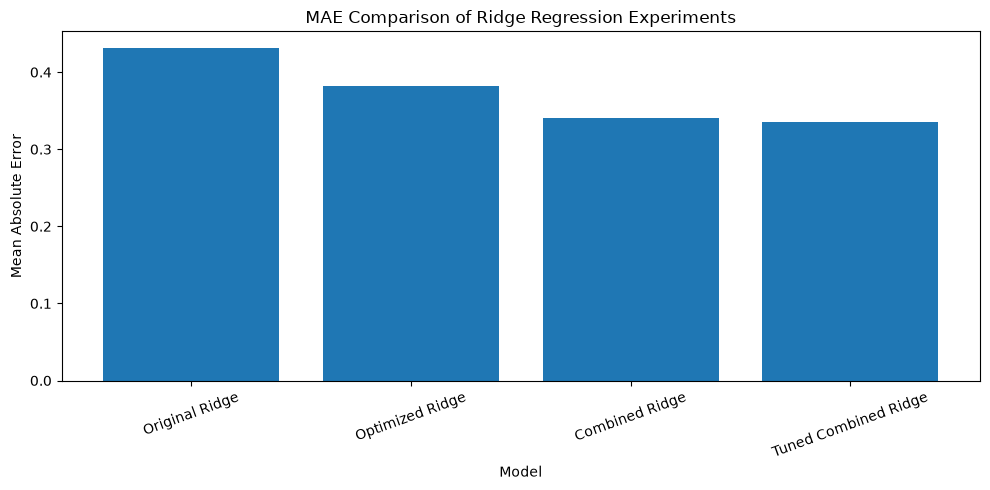

In [46]:
models = [
    "Original Ridge",
    "Optimized Ridge",
    "Combined Ridge",
    "Tuned Combined Ridge"
]

mae_values = [
    0.431381,
    0.382466,
    0.340627,
    0.335374
]

plt.figure(figsize=(10, 5))

plt.bar(models, mae_values)

plt.title("MAE Comparison of Ridge Regression Experiments")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [47]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    max_depth=30,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

dt_model.fit(
    X_train_combined_tfidf,
    y_train_combined
)

dt_predictions = dt_model.predict(X_test_combined_tfidf)

dt_mae = mean_absolute_error(y_test_combined, dt_predictions)
dt_mse = mean_squared_error(y_test_combined, dt_predictions)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test_combined, dt_predictions)

print("Decision Tree Regression Performance")
print("-------------------------------------")
print("MAE:", dt_mae)
print("MSE:", dt_mse)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)

Decision Tree Regression Performance
-------------------------------------
MAE: 0.3854169234524265
MSE: 0.45636143108494137
RMSE: 0.6755452842592725
R2 Score: 0.47797388152315234


In [48]:
from sklearn.svm import LinearSVR

svr_model = LinearSVR(
    C=1.0,
    epsilon=0.1,
    max_iter=5000,
    random_state=42
)

svr_model.fit(
    X_train_combined_tfidf,
    y_train_combined
)

svr_predictions = svr_model.predict(X_test_combined_tfidf)

svr_mae = mean_absolute_error(y_test_combined, svr_predictions)
svr_mse = mean_squared_error(y_test_combined, svr_predictions)
svr_rmse = np.sqrt(svr_mse)
svr_r2 = r2_score(y_test_combined, svr_predictions)

print("LinearSVR Regression Performance")
print("---------------------------------")
print("MAE:", svr_mae)
print("MSE:", svr_mse)
print("RMSE:", svr_rmse)
print("R2 Score:", svr_r2)

LinearSVR Regression Performance
---------------------------------
MAE: 0.3237528138951968
MSE: 0.27605443795407125
RMSE: 0.5254088293453691
R2 Score: 0.6842247900071792


In [49]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVR

svr_params = {
    "C": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0],
    "epsilon": [0.05, 0.1, 0.2, 0.3]
}

svr_grid = GridSearchCV(
    LinearSVR(max_iter=10000, random_state=42),
    svr_params,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

svr_grid.fit(
    X_train_combined_tfidf,
    y_train_combined
)

print("Best Parameters:", svr_grid.best_params_)
print("Best CV MAE:", -svr_grid.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters: {'C': 2.0, 'epsilon': 0.05}
Best CV MAE: 0.3272000707427702


In [50]:
best_svr_model = svr_grid.best_estimator_

best_svr_predictions = best_svr_model.predict(
    X_test_combined_tfidf
)

best_svr_mae = mean_absolute_error(
    y_test_combined, best_svr_predictions
)

best_svr_mse = mean_squared_error(
    y_test_combined, best_svr_predictions
)

best_svr_rmse = np.sqrt(best_svr_mse)

best_svr_r2 = r2_score(
    y_test_combined, best_svr_predictions
)

print("Tuned LinearSVR Performance")
print("---------------------------")
print("MAE:", best_svr_mae)
print("MSE:", best_svr_mse)
print("RMSE:", best_svr_rmse)
print("R2 Score:", best_svr_r2)

Tuned LinearSVR Performance
---------------------------
MAE: 0.31249631695728564
MSE: 0.27508850432247806
RMSE: 0.524488802857104
R2 Score: 0.6853297093760402


In [51]:
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_combined,
    y_combined,
    test_size=0.2,
    random_state=101,
    stratify=y_combined
)

print("Final Training Data:", X_train_final.shape)
print("Final Testing Data:", X_test_final.shape)

Final Training Data: (22648,)
Final Testing Data: (5663,)


In [52]:
from sklearn.feature_extraction.text import TfidfVectorizer

final_tfidf = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 3)
)

X_train_final_tfidf = final_tfidf.fit_transform(X_train_final)

X_test_final_tfidf = final_tfidf.transform(X_test_final)

print("Training TF-IDF Shape:", X_train_final_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_final_tfidf.shape)


Training TF-IDF Shape: (22648, 15000)
Testing TF-IDF Shape: (5663, 15000)


In [53]:
from sklearn.linear_model import Ridge
from sklearn.svm import LinearSVR

# 1. Train Ridge Regression
final_ridge = Ridge(alpha=0.25)

final_ridge.fit(
    X_train_final_tfidf,
    y_train_final
)

ridge_final_predictions = final_ridge.predict(
    X_test_final_tfidf
)


# 2. Train LinearSVR
final_svr = LinearSVR(
    C=2.0,
    epsilon=0.05,
    max_iter=10000,
    random_state=42
)

final_svr.fit(
    X_train_final_tfidf,
    y_train_final
)

svr_final_predictions = final_svr.predict(
    X_test_final_tfidf
)

print("Both final models trained successfully!")

Both final models trained successfully!


In [54]:
# Evaluate Ridge
ridge_mae_final = mean_absolute_error(
    y_test_final, ridge_final_predictions
)

ridge_mse_final = mean_squared_error(
    y_test_final, ridge_final_predictions
)

ridge_rmse_final = np.sqrt(ridge_mse_final)

ridge_r2_final = r2_score(
    y_test_final, ridge_final_predictions
)


# Evaluate LinearSVR
svr_mae_final = mean_absolute_error(
    y_test_final, svr_final_predictions
)

svr_mse_final = mean_squared_error(
    y_test_final, svr_final_predictions
)

svr_rmse_final = np.sqrt(svr_mse_final)

svr_r2_final = r2_score(
    y_test_final, svr_final_predictions
)


# Display comparison
final_comparison = pd.DataFrame({
    "Model": ["Ridge Regression", "LinearSVR"],
    "MAE": [ridge_mae_final, svr_mae_final],
    "MSE": [ridge_mse_final, svr_mse_final],
    "RMSE": [ridge_rmse_final, svr_rmse_final],
    "R2 Score": [ridge_r2_final, svr_r2_final]
})

print("FINAL MODEL EVALUATION")
print("----------------------")

display(final_comparison.round(4))

FINAL MODEL EVALUATION
----------------------


,Model,MAE,MSE,RMSE,R2 Score
0,Ridge Regression,0.3318,0.2391,0.4889,0.7265
1,LinearSVR,0.3091,0.2709,0.5205,0.6901


In [55]:
# Calculate residuals
final_residuals = y_test_final - ridge_final_predictions

print("Final Ridge Residual Analysis")
print("-----------------------------")

print("Mean Residual:", np.mean(final_residuals))
print("Standard Deviation:", np.std(final_residuals))
print("Minimum Residual:", np.min(final_residuals))
print("Maximum Residual:", np.max(final_residuals))

Final Ridge Residual Analysis
-----------------------------
Mean Residual: -0.002339707098090727
Standard Deviation: 0.4889294926043357
Minimum Residual: -2.9357327499397465
Maximum Residual: 2.615633525634964


In [56]:
import joblib
import os
import json

# Create directory
os.makedirs("../models/regression", exist_ok=True)

# Save trained Ridge model
joblib.dump(
    final_ridge,
    "../models/regression/final_ridge_model.pkl"
)

# Save TF-IDF vectorizer
joblib.dump(
    final_tfidf,
    "../models/regression/final_tfidf_vectorizer.pkl"
)

# Save model information
model_info = {
    "model": "Ridge Regression",
    "alpha": 0.25,
    "max_features": 15000,
    "ngram_range": [1, 3],
    "MAE": float(ridge_mae_final),
    "MSE": float(ridge_mse_final),
    "RMSE": float(ridge_rmse_final),
    "R2_Score": float(ridge_r2_final)
}

with open(
    "../models/regression/model_info.json",
    "w"
) as file:
    json.dump(model_info, file, indent=4)

print("Final model saved successfully!")
print("TF-IDF vectorizer saved successfully!")
print("Model information saved successfully!")

Final model saved successfully!
TF-IDF vectorizer saved successfully!
Model information saved successfully!


Final Comparision of all the model.

In [57]:
import pandas as pd

model_comparison = [
    ["Mean Baseline", "Average rating", 0.6827, 0.8742, 0.9350, 0.0000],
    ["Linear Regression", "5K TF-IDF, Review Only", 0.4641, 0.4212, 0.6490, 0.5182],
    ["Ridge Regression", "5K TF-IDF, Alpha=1.0", 0.4314, 0.3659, 0.6049, 0.5815],
    ["Random Forest", "100 Estimators, Depth=20", 0.4570, 0.4217, 0.6494, 0.5176],
    ["Ridge Regression", "10K TF-IDF, N-gram=(1,2)", 0.4068, None, 0.5753, 0.6214],
    ["Ridge Regression", "15K TF-IDF, N-gram=(1,2)", 0.3974, None, 0.5661, 0.6335],
    ["Ridge Regression", "10K TF-IDF, N-gram=(1,3)", 0.4064, None, 0.5756, 0.6211],
    ["Ridge Regression", "15K TF-IDF, N-gram=(1,3)", 0.3928, None, 0.5607, 0.6404],
    ["Ridge Regression", "Review Only, Alpha=0.5", 0.3825, 0.3029, 0.5504, 0.6535],
    ["Ridge Regression", "Title + Review, Alpha=0.5", 0.3406, 0.2511, 0.5011, 0.7128],
    ["Ridge Regression", "Title + Review, Alpha=0.25", 0.3354, 0.2495, 0.4995, 0.7146],
    ["Linear Regression", "Title + Review", 2.1271, 25.6921, 5.0687, -28.3889],
    ["ElasticNet", "Alpha=0.001, L1 Ratio=0.5", 0.5003, 0.4922, 0.7015, 0.4370],
    ["Decision Tree", "Max Depth=30", 0.3854, 0.4564, 0.6755, 0.4780],
    ["LinearSVR", "C=1.0, Epsilon=0.1", 0.3238, 0.2761, 0.5254, 0.6842],
    ["LinearSVR", "C=2.0, Epsilon=0.05", 0.3125, 0.2751, 0.5245, 0.6853]
]

comparison_df = pd.DataFrame(
    model_comparison,
    columns=[
        "Model",
        "Configuration",
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score"
    ]
)

comparison_df.index = range(1, len(comparison_df) + 1)

comparison_df

,Model,Configuration,MAE,MSE,RMSE,R2 Score
1,Mean Baseline,Average rating,0.6827,0.8742,0.9350,0.0000
2,Linear Regression,"5K TF-IDF, Review Only",0.4641,0.4212,0.6490,0.5182
3,Ridge Regression,"5K TF-IDF, Alpha=1.0",0.4314,0.3659,0.6049,0.5815
4,Random Forest,"100 Estimators, Depth=20",0.4570,0.4217,0.6494,0.5176
5,Ridge Regression,"10K TF-IDF, N-gram=(1,2)",0.4068,NaN,0.5753,0.6214
6,Ridge Regression,"15K TF-IDF, N-gram=(1,2)",0.3974,NaN,0.5661,0.6335
7,Ridge Regression,"10K TF-IDF, N-gram=(1,3)",0.4064,NaN,0.5756,0.6211
8,Ridge Regression,"15K TF-IDF, N-gram=(1,3)",0.3928,NaN,0.5607,0.6404
9,Ridge Regression,"Review Only, Alpha=0.5",0.3825,0.3029,0.5504,0.6535
10,Ridge Regression,"Title + Review, Alpha=0.5",0.3406,0.2511,0.5011,0.7128


In [58]:
final_comparison = [
    ["Ridge Regression", 0.3318, 0.2391, 0.4889, 0.7265],
    ["LinearSVR", 0.3091, 0.2709, 0.5205, 0.6901]
]

final_comparison_df = pd.DataFrame(
    final_comparison,
    columns=[
        "Model",
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score"
    ]
)

final_comparison_df

,Model,MAE,MSE,RMSE,R2 Score
0,Ridge Regression,0.3318,0.2391,0.4889,0.7265
1,LinearSVR,0.3091,0.2709,0.5205,0.6901


In [59]:
final_comparison_df.style.highlight_min(
    subset=["MAE", "MSE", "RMSE"],
    color="lightgreen"
).highlight_max(
    subset=["R2 Score"],
    color="lightgreen"
).format({
    "MAE": "{:.4f}",
    "MSE": "{:.4f}",
    "RMSE": "{:.4f}",
    "R2 Score": "{:.4f}"
})

,Model,MAE,MSE,RMSE,R2 Score
0,Ridge Regression,0.3318,0.2391,0.4889,0.7265
1,LinearSVR,0.3091,0.2709,0.5205,0.6901


In [60]:
import os

os.makedirs("../results", exist_ok=True)

comparison_df.to_csv(
    "../results/all_model_comparison.csv",
    index=True
)

final_comparison_df.to_csv(
    "../results/final_model_comparison.csv",
    index=False
)

print("Complete model comparison saved!")
print("Final model comparison saved!")

Complete model comparison saved!
Final model comparison saved!


In [61]:
import joblib

# Load the final trained Ridge model
loaded_model = joblib.load(
    "../models/regression/final_ridge_model.pkl"
)

# Load the fitted TF-IDF vectorizer
loaded_tfidf = joblib.load(
    "../models/regression/final_tfidf_vectorizer.pkl"
)

print("Final Ridge model loaded successfully!")
print("Final TF-IDF vectorizer loaded successfully!")

print("\nModel:", loaded_model)
print("TF-IDF Features:", loaded_tfidf.max_features)

Final Ridge model loaded successfully!
Final TF-IDF vectorizer loaded successfully!

Model: Ridge(alpha=0.25)
TF-IDF Features: 15000


In [62]:
# Sample preprocessed product reviews
new_reviews = [
    "excellent battery life work perfectly great quality",
    "terrible product stop work after two day",
    "good product value money easy use",
    "poor quality not work properly disappointed"
]

# Convert reviews into TF-IDF features
new_reviews_tfidf = loaded_tfidf.transform(new_reviews)

# Predict ratings
predictions = loaded_model.predict(new_reviews_tfidf)

# Display predictions
for review, prediction in zip(new_reviews, predictions):
    predicted_rating = max(1, min(5, prediction))

    print("Review:", review)
    print("Predicted Rating:", round(predicted_rating, 2))
    print("-" * 60)

Review: excellent battery life work perfectly great quality
Predicted Rating: 5
------------------------------------------------------------
Review: terrible product stop work after two day
Predicted Rating: 1.48
------------------------------------------------------------
Review: good product value money easy use
Predicted Rating: 4.47
------------------------------------------------------------
Review: poor quality not work properly disappointed
Predicted Rating: 1.32
------------------------------------------------------------


In [63]:
# Select 10 actual unseen reviews
sample_reviews = X_test_final.iloc[:10]

# Get their actual ratings
actual_ratings = y_test_final.iloc[:10]

# Transform using the saved TF-IDF vectorizer
sample_tfidf = loaded_tfidf.transform(sample_reviews)

# Predict ratings
predicted_ratings = loaded_model.predict(sample_tfidf)

# Create comparison table
testing_results = pd.DataFrame({
    "Review": sample_reviews.values,
    "Actual Rating": actual_ratings.values,
    "Predicted Rating": predicted_ratings.round(2)
})

testing_results

,Review,Actual Rating,Predicted Rating
0,Easy to use easy use simple use setup 2 year o...,4,4.26
1,Loses WI Fi Constantly loses wi fi constantly ...,3,3.80
2,"Came in for a charger, bought a new phone - G7...",5,4.71
3,Two Stars battery not last long,2,1.75
4,We aren't running out of batteries now for gam...,4,4.28
5,Niece loves it niece love tablet product work ...,4,4.65
6,Four Stars seem good major aa's new really rate,4,3.91
7,Five Stars great price battery fully charge,5,4.83
8,Five Stars never buy battery anywhere else,5,5.03
9,Five Stars great price,5,5.00


In [64]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

actual = actual_ratings.values
predicted = predicted_ratings

mae = mean_absolute_error(actual, predicted)
mse = mean_squared_error(actual, predicted)
rmse = np.sqrt(mse)
r2 = r2_score(actual, predicted)

print("10-Sample Prediction Evaluation")
print("--------------------------------")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

10-Sample Prediction Evaluation
--------------------------------
MAE: 0.2817
MSE: 0.1387
RMSE: 0.3724
R2 Score: 0.8441


In [65]:
from src.prediction.regression import predict_rating

# Sample preprocessed review
review = "excellent battery life work perfectly great quality"

# Predict rating
predicted_rating = predict_rating(review)

print("Review:", review)
print("Predicted Rating:", predicted_rating)

ModuleNotFoundError: No module named 'src'

In [66]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders:")
print(os.listdir())

Current working directory:
c:\5th sem\ML\ML Project\Product-Review-Rating-Prediction-and-Clustering\notebooks

Files and folders:
['regression_experiment.ipynb']


In [67]:
import os
import sys

# Move one directory above notebooks
project_root = os.path.dirname(os.getcwd())

# Add project root to Python path
sys.path.insert(0, project_root)

print("Project root:", project_root)

print("src folder exists:",
      os.path.exists(os.path.join(project_root, "src")))

Project root: c:\5th sem\ML\ML Project\Product-Review-Rating-Prediction-and-Clustering
src folder exists: True


In [68]:
from src.prediction.regression import predict_rating

print("Prediction module imported successfully!")

Prediction module imported successfully!


In [69]:
review = "excellent battery life work perfectly great quality"

predicted_rating = predict_rating(review)

print("Predicted Rating:", predicted_rating)

Predicted Rating: 5.0


In [70]:
import importlib
import src.prediction.regression as regression

importlib.reload(regression)

prediction = regression.predict_rating(
    review_text="excellent battery life work perfectly great quality"
)

print("Predicted Rating:", prediction)

Predicted Rating: 5.0


In [71]:
try:
    regression.predict_rating(review_text="")
except ValueError as e:
    print("Validation Working:", e)

Validation Working: Review text cannot be empty.


In [72]:
test_reviews = [
    {
        "title": "Excellent product",
        "text": "battery life work perfectly great quality"
    },
    {
        "title": "Worst experience",
        "text": "terrible product stop work after two day"
    },
    {
        "title": "Good value",
        "text": "good product value money easy use"
    },
    {
        "title": "Very disappointing",
        "text": "poor quality not work properly disappointed"
    }
]

for review in test_reviews:
    prediction = regression.predict_rating(
        review_text=review["text"],
        review_title=review["title"]
    )

    print(f"Title: {review['title']}")
    print(f"Predicted Rating: {prediction}/5")
    print("-" * 40)

Title: Excellent product
Predicted Rating: 4.74/5
----------------------------------------
Title: Worst experience
Predicted Rating: 1.0/5
----------------------------------------
Title: Good value
Predicted Rating: 4.31/5
----------------------------------------
Title: Very disappointing
Predicted Rating: 1.0/5
----------------------------------------


In [1]:
import nltk

resources = [
    "corpora/stopwords",
    "corpora/wordnet",
    "corpora/omw-1.4",
    "taggers/averaged_perceptron_tagger_eng"
]

for resource in resources:
    try:
        nltk.data.find(resource)
        print(f"Available: {resource}")
    except LookupError:
        print(f"Missing: {resource}")

Missing: corpora/stopwords
Missing: corpora/wordnet
Missing: corpora/omw-1.4
Missing: taggers/averaged_perceptron_tagger_eng


In [2]:
import nltk

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("averaged_perceptron_tagger")
nltk.download("averaged_perceptron_tagger_eng")

[nltk_data] Downloading package stopwords to C:\Users\HP
[nltk_data]     LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to C:\Users\HP
[nltk_data]     LENOVO\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to C:\Users\HP
[nltk_data]     LENOVO\AppData\Roaming\nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\HP LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping taggers\averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\HP LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping taggers\averaged_perceptron_tagger_eng.zip.


True

In [3]:
import os
import sys

project_root = os.path.dirname(os.getcwd())
sys.path.insert(0, project_root)

from src.preprocessing.text_cleaning import preprocess_review

title = "Excellent Product"

review = "This product is very good. I am happy with the quality and performance. It works perfectly."

result = preprocess_review(review, title)

print("Original Review:")
print(review)

print("\nPreprocessed Review:")
print(result)

Original Review:
This product is very good. I am happy with the quality and performance. It works perfectly.

Preprocessed Review:
excellent product product good happy quality performance work perfectly


In [4]:
from src.preprocessing.text_cleaning import preprocess_review

sample_title = "Excellent product"

sample_review = (
    "This product is very good. "
    "I am happy with the quality and performance. "
    "It works perfectly."
)

result = preprocess_review(
    sample_review,
    sample_title
)

print("Preprocessed Review:")
print(result)

Preprocessed Review:
excellent product product good happy quality performance work perfectly


In [5]:
import importlib
import src.prediction.regression as regression

importlib.reload(regression)

from src.prediction.regression import predict_rating


# Raw customer review
title = "Excellent product"

review = (
    "This product is very good. "
    "I am happy with the quality and performance. "
    "It works perfectly."
)

predicted_rating = predict_rating(
    review_text=review,
    review_title=title
)

print("Review Title:", title)
print("Customer Review:", review)
print("Predicted Rating:", predicted_rating, "/ 5")

Review Title: Excellent product
Customer Review: This product is very good. I am happy with the quality and performance. It works perfectly.
Predicted Rating: 4.64 / 5


In [6]:
test_reviews = [
    ("Excellent product", "Amazing quality and excellent performance."),
    ("Worst experience", "Very poor quality. Completely disappointed."),
    ("Good value", "Good product for the price. Works well."),
    ("Very disappointing", "Stopped working after two days. Terrible product."),
    ("Average product", "Quality is okay. Nothing special.")
]

for title, review in test_reviews:

    rating = predict_rating(
        review_text=review,
        review_title=title
    )

    print("Title:", title)
    print("Predicted Rating:", rating, "/ 5")
    print("-" * 50)

Title: Excellent product
Predicted Rating: 4.45 / 5
--------------------------------------------------
Title: Worst experience
Predicted Rating: 1.43 / 5
--------------------------------------------------
Title: Good value
Predicted Rating: 4.18 / 5
--------------------------------------------------
Title: Very disappointing
Predicted Rating: 2.21 / 5
--------------------------------------------------
Title: Average product
Predicted Rating: 3.55 / 5
--------------------------------------------------
